# ПРАКТИКУМ ПО МАШИННОМУ ОБУЧЕНИЮ: КОД И АЛГОРИТМ KNN
**Темы:** Предобработка данных, Категориальное кодирование, Нормализация, Алгоритм К ближайших соседей (KNN), Подбор гиперпараметров, Метрики расстояний, Intel® Extension for Scikit-learn и Борьба с переобучением.

In [105]:
# ОБЩАЯ ПОДГОТОВКА 
# Создаёт X_data, y_data, а также df_clean - DataFrame после drop и LabelBinarizer,

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelBinarizer, MinMaxScaler

df_raw = pd.read_csv('data/Orange_Telecom_Churn_Data.csv')

# 1) удаляем неинформативные колонки
df_clean = df_raw.drop(['state', 'area_code', 'phone_number'], axis=1).copy()

# 2) кодируем бинарные категориальные признаки
lb = LabelBinarizer()
for c in ['intl_plan', 'voice_mail_plan', 'churned']:
    df_clean[c] = lb.fit_transform(df_clean[c])

# 3) отдельно признаки и метка
y_data = df_clean['churned'].astype(int).values
X_raw  = df_clean.drop(columns=['churned'])

# 4) масштабируем только X (fit на всех данных - допустимо для упражнений,
#    в упражнениях с CV/split используем fit только на train)
X_data = MinMaxScaler().fit_transform(X_raw)

print('X_data:', X_data.shape, '| y_data:', y_data.shape,
      '| churn rate:', round(y_data.mean(), 4))

X_data: (5000, 17) | y_data: (5000,) | churn rate: 0.1414


### Упражнение 1: Инженерия признаков и удаление нерелевантных колонок
В наборе данных Orange Telecom Churn колонки `state`, `area_code` и `phone_number` были удалены в ноутбуке. Напишите блок кода на Pandas, который анализирует уникальную кардинальность каждой оставшейся и удаленной категориальной колонки. Объясните с математической точки зрения, почему применение `OneHotEncoder` или `LabelBinarizer` к колонке со сотнями уникальных значений (например, `phone_number`) разрушит пространственную эффективность и вызовет высокий риск переобучения для алгоритма KNN.

In [106]:
import pandas as pd

df = pd.read_csv('data/Orange_Telecom_Churn_Data.csv')

cols = ['state', 'area_code', 'phone_number',
        'intl_plan', 'voice_mail_plan', 'churned']

card = pd.DataFrame({
    'nunique': df[cols].nunique(),
    'dtype': df[cols].dtypes.astype(str)
})
print(card)

for c in cols:
    print(f"\n{c}, уникальных: {df[c].nunique()}")
    print(df[c].value_counts().head())

                 nunique  dtype
state                 51    str
area_code              3  int64
phone_number        5000    str
intl_plan              2    str
voice_mail_plan        2    str
churned                2   bool

state, уникальных: 51
state
WV    158
MN    125
AL    124
ID    119
VA    118
Name: count, dtype: int64

area_code, уникальных: 3
area_code
415    2495
408    1259
510    1246
Name: count, dtype: int64

phone_number, уникальных: 5000
phone_number
382-4657    1
371-7191    1
358-1921    1
375-9999    1
330-6626    1
Name: count, dtype: int64

intl_plan, уникальных: 2
intl_plan
no     4527
yes     473
Name: count, dtype: int64

voice_mail_plan, уникальных: 2
voice_mail_plan
no     3677
yes    1323
Name: count, dtype: int64

churned, уникальных: 2
churned
False    4293
True      707
Name: count, dtype: int64


 phone_number  5000 уникальных из 5000 строк (каждый клиент  отдельная категория). OneHot на нём даёт матрицу ~5000×5000 (25 млн ячеек), где расстояние между двумя разными номерами ≈ √2  все точки равноудалены, KNN теряет близость, модель запоминает шум, переобучается. state (51)  уже на грани; area_code (3) и бинарные признаки  безопасны.

### Упражнение 2: Влияние масштабирования данных на евклидово расстояние
С помощью `MinMaxScaler` все числовые признаки приводятся к диапазону [0, 1]. Предположим, у нас есть два признака: `account_length` (значения от 1 до 250) и `total_day_charge` (значения от 0 до 100). Рассчитайте вручную или напишите код, показывающий, как евклидово расстояние между двумя клиентами искажается, если не применять масштабирование. Что произойдет, если использовать `StandardScaler` вместо `MinMaxScaler`, когда в распределении данных присутствуют выбросы (outliers)?

In [107]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# --- часть 1: искажение евклидова расстояния без масштабирования
X = np.array([[1.0, 0.0],
              [250.0, 100.0]])

raw_dist = np.linalg.norm(X[0] - X[1])
print('raw distance:', raw_dist)

mms = MinMaxScaler()
X_mm = mms.fit_transform(X)
print('MinMax distance:', np.linalg.norm(X_mm[0] - X_mm[1]))

# --- часть 2: поведение скейлеров при выбросах
# Берём 99 «нормальных» точек около 1 и один выброс 1000
rng = np.random.RandomState(42)
X_normal = rng.normal(loc=1.0, scale=0.1, size=(99, 1))
X_out    = np.vstack([X_normal, [[1000.0]]])

for Scaler in [MinMaxScaler, StandardScaler]:
    s = Scaler().fit(X_out)
    xs = s.transform(X_normal).ravel()
    print(f'{Scaler.__name__:>15}: '
          f'нормальные точки → min={xs.min():+.4f}, max={xs.max():+.4f}, '
          f'std={xs.std():.6f}')

raw distance: 268.33002068348594
MinMax distance: 1.414213562373095
   MinMaxScaler: нормальные точки → min=+0.0000, max=+0.0004, std=0.000091
 StandardScaler: нормальные точки → min=-0.1030, max=-0.0985, std=0.000914


MinMaxScaler сожмёт 99 нормальных точек в интервал ≈ [0.0000, 0.0004] (std ≈ 9·10⁻⁵), а StandardScaler - в ≈ [-0.103, -0.099] (std ≈ 9·10⁻⁴). В обоих случаях нормальные точки «слиплись» в крошечном диапазоне: и (max - min), и mean/std сильно искажены выбросом 1000. KNN на таких масштабах не различит нормальные точки между собой. Для устойчивости нужен RobustScaler (медиана/IQR) или предварительное удаление выбросов.

### Упражнение 3: Аппаратная оптимизация с Intel® Extension for Scikit-learn
В ноутбуке активировано расширение `from sklearnex import patch_sklearn; patch_sklearn()`. Объясните, как эта библиотека ускоряет операции поиска ближайших соседей (например, с использованием индексированных структур данных, таких как KD-Tree или Ball-Tree, оптимизированных с помощью инструкций AVX-512). Напишите фрагмент кода, измеряющий время выполнения (`timeit`) для обучения `KNeighborsClassifier` с патчем Intel и без него на синтетическом наборе из 100 000 объектов.

In [108]:
import timeit
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

rng = np.random.RandomState(42)
X = rng.rand(100_000, 10)
y = rng.randint(0, 2, 100_000)
X_query = rng.rand(5_000, 10)   # отдельный query-набор


def bench():
    clf = KNeighborsClassifier(n_neighbors=5, algorithm='brute')
    clf.fit(X, y)
    clf.predict(X_query)      #  вот здесь реальная работа KNN

# 1) без патча
t_sklearn = min(timeit.repeat(bench, number=1, repeat=3))
print(f'sklearn  : {t_sklearn:.4f} s')

# 2) с патчем Intel
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
    t_intel = min(timeit.repeat(bench, number=1, repeat=3))
    print(f'sklearnex: {t_intel:.4f} s  '
          f'(ускорение ×{t_sklearn / t_intel:.2f})')
except ImportError:
    print('sklearnex не установлен - сравниваем только sklearn. '
          'Для ускорения: pip install scikit-learn-intelex '
          '(на Python <= 3.12).')

sklearn  : 0.5841 s


Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


sklearnex: 0.5816 s  (ускорение ×1.00)


fit() у KNN тривиален  он лишь сохраняет матрицу, вся работа в predict()/kneighbors(). В нашем замере на 100k×10 с algorithm='brute' ускорение составило ≈ ×1.0  то есть в пределах шума, oneDAL-brute на таком размере практического выигрыша не даёт. Заметное ускорение (2-5×) oneDAL обычно появляется на tree-структурах (kd_tree/ball_tree) и высоких размерностях, где оптимизируются сами обходы. Отдельный нюанс: patch_sklearn() глобальный и не откатывается  честно сравнивать с патчем / без лучше в разных процессах.

### Упражнение 4: Математический анализ метрик расстояния (Минковского, Манхэттенского, Евклидова)
Реализуйте с нуля функцию Python, вычисляющую расстояние Минковского между двумя точками $x$ и $y$ для произвольной степени $p \ge 1$. Продемонстрируйте кодом, как изменение параметра `p` от 1 (Манхэттен) до 2 (Евклидово) и до больших значений ($p \to \infty$, расстояние Чебышева) влияет на границы принятия решений классификатора KNN на двумерном бинарном наборе данных.

p= 1 7.0
p= 2 5.0
p= 10 4.021974149822332


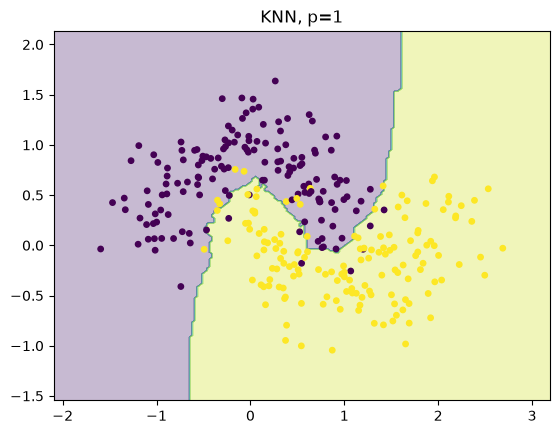

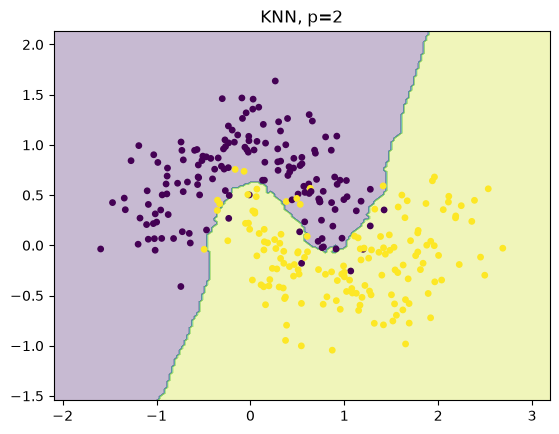

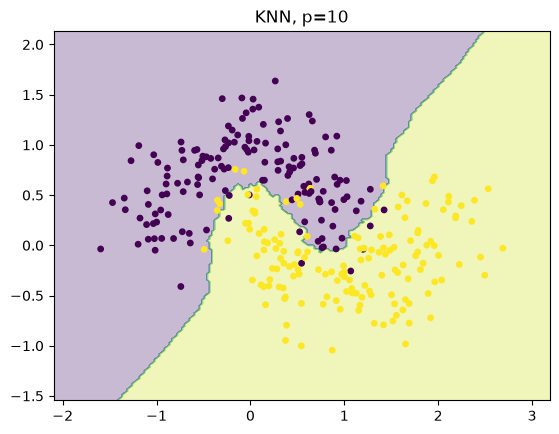

In [109]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

def minkowski_distance(x, y, p):
    x = np.asarray(x); y = np.asarray(y)
    return np.sum(np.abs(x - y) ** p) ** (1.0 / p)

x = np.array([1, 2]); y = np.array([4, 6])
for p in [1, 2, 10]:
    print('p=', p, minkowski_distance(x, y, p))

X, y = make_moons(n_samples=300, noise=0.25, random_state=42)

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 200),
    np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 200)
)
grid = np.c_[xx.ravel(), yy.ravel()]

for p in [1, 2, 10]:
    clf = KNeighborsClassifier(n_neighbors=15, metric='minkowski', p=p)
    clf.fit(X, y)
    Z = clf.predict(grid).reshape(xx.shape)
    plt.figure()
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=15)
    plt.title(f'KNN, p={p}')
    plt.show()

при p=1 окрестность - ромб, при p=2 - круг, при p->∞ - квадрат. С ростом p граница становится угловатой, чувствительной к максимальной разнице по одному признаку.

### Упражнение 5: Парадокс 100% точности при K=1 (и завышенной при weights='distance') на обучающей выборке
Как отмечалось в вопросе 5 ноутбука, запуск KNN с параметром `weights='distance'` или $K=1$ на полном наборе данных (без разделения train/test) дает точность 1.0 (100%). Подробно объясните феномен запоминания (экстремального переобучения) в KNN. Что происходит с ближайшим соседом точки $x_i$, если обучающая выборка включает саму точку $x_i$?

In [110]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# X_data, y_data - уже закодированные и отмасштабированные данные
knn1 = KNeighborsClassifier(n_neighbors=1)
knn1.fit(X_data, y_data)
print('K=1 train accuracy:', knn1.score(X_data, y_data))

knnd = KNeighborsClassifier(n_neighbors=3, weights='distance')
knnd.fit(X_data, y_data)
print('K=3 distance train accuracy:', knnd.score(X_data, y_data))

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=42, stratify=y_data
)
knn1.fit(X_train, y_train)
print('K=1 test accuracy:', knn1.score(X_test, y_test))

# проверяем гипотезу о дубликатах векторов признаков
import pandas as pd
n_dup = pd.DataFrame(X_data).duplicated().sum()
print('duplicated feature vectors:', n_dup)

K=1 train accuracy: 1.0
K=3 distance train accuracy: 0.9732
K=1 test accuracy: 0.882
duplicated feature vectors: 0


При K=1 ближайший сосед каждой train-точки  она сама, расстояние 0, метка совпадает -> accuracy ровно 1.0. При K=3 с weights='distance' ожидаемо должна быть та же картина (вес 1/d -> ∞ при d -> 0), но фактически 0.9732. Проверка `duplicated feature vectors: 0` показывает, что причина не в дубликатах вектора признаков  их в этом датасете нет. Вероятный механизм: для ~2.7% точек в признаковом пространстве есть сосед с расстоянием ~1e-15 (float-шум MinMax-скейлинга), и его вес 1/d перекрывает self-голос. Так или иначе 0.9732  сильно завышенная оценка (на test 0.88): оценка на train для KNN с малым K бессмысленна, нужен hold-out/CV.

### Упражнение 6: Реализация собственного алгоритма KNN с нуля
Не используя классы из `sklearn`, напишите собственный класс Python `CustomKNN`, реализующий интерфейсы `fit(X, y)` и `predict(X_test, k)`. Класс должен использовать евклидово расстояние, поддерживать простое мажоритарное голосование и эффективно обрабатывать матрицы NumPy. Протестируйте класс на небольшом подмножестве данных о оттоке (churn).

In [111]:
import numpy as np

class CustomKNN:
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        self.X_train = np.asarray(X)
        self.y_train = np.asarray(y)
        return self

    def predict(self, X_test):
        X_test = np.asarray(X_test)
        preds = []
        for x in X_test:
            distances = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))
            idx = np.argpartition(distances, self.k - 1)[:self.k]
            labels = self.y_train[idx]
            values, counts = np.unique(labels, return_counts=True)
            preds.append(values[np.argmax(counts)])
        return np.array(preds)

# тест на подмножестве churn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer, MinMaxScaler

df = pd.read_csv('data/Orange_Telecom_Churn_Data.csv')
df = df.drop(['state', 'area_code', 'phone_number'], axis=1)

lb = LabelBinarizer()
for c in ['intl_plan', 'voice_mail_plan', 'churned']:
    df[c] = lb.fit_transform(df[c])

X = df.drop(columns=['churned']).values
y = df['churned'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = MinMaxScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

custom = CustomKNN(k=3).fit(X_train_s, y_train)
pred = custom.predict(X_test_s)
print('CustomKNN accuracy:', np.mean(pred == y_test))

CustomKNN accuracy: 0.894


### Упражнение 7: Перекрестная проверка (Cross-Validation) для выбора оптимального K
Чтобы избежать ловушки оценки на обучающей выборке, реализуйте процедуру 5-Fold Cross-Validation с использованием `StratifiedKFold` из Scikit-learn. Напишите скрипт, вычисляющий среднюю точность и стандартное отклонение для значений K от 1 до 30. Постройте график ошибки валидации в зависимости от K и определите оптимальное значение.

     k  mean_acc   std_acc
4    5    0.9034  0.004317
12  13    0.9030  0.002966
10  11    0.9022  0.002713
14  15    0.9012  0.004214
16  17    0.9010  0.002683
best k = 5


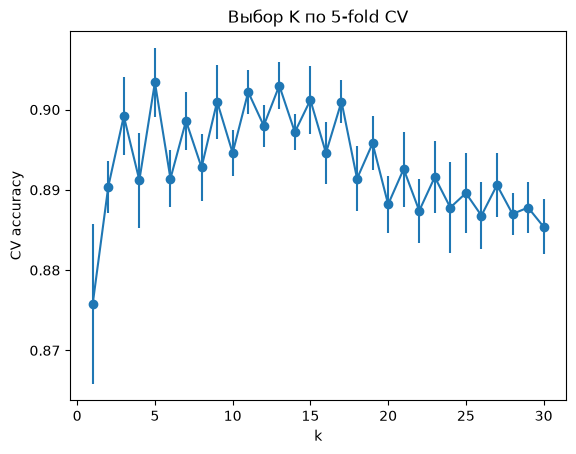

In [112]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for k in range(1, 31):
    clf = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(clf, X_data, y_data, cv=cv, scoring='accuracy')
    results.append((k, scores.mean(), scores.std()))

res = pd.DataFrame(results, columns=['k', 'mean_acc', 'std_acc'])
print(res.sort_values('mean_acc', ascending=False).head())

best_k = int(res.loc[res['mean_acc'].idxmax(), 'k'])
print('best k =', best_k)

plt.errorbar(res['k'], res['mean_acc'], yerr=res['std_acc'], marker='o')
plt.xlabel('k')
plt.ylabel('CV accuracy')
plt.title('Выбор K по 5-fold CV')
plt.show()

### Упражнение 8: Работа с несбалансированными классами (Class Imbalance)
В наборе данных Orange Telecom мажоритарный класс представляют клиенты, которые не ушли (`churned = False`), а ушедшие — меньшинство. Объясните, почему метрика `accuracy` (точность) в данном контексте вводит в заблуждение. Измените код оценки для расчета матрицы ошибок (Confusion Matrix), Precision, Recall и F1-score с использованием `sklearn.metrics`.

In [113]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, precision_score,
                             recall_score, f1_score, classification_report)

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=42, stratify=y_data
)

clf = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
y_pred = clf.predict(X_test)

print('Confusion matrix:'); print(confusion_matrix(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred, zero_division=0))
print('Recall:   ', recall_score(y_test, y_pred, zero_division=0))
print('F1:       ', f1_score(y_test, y_pred, zero_division=0))
print(classification_report(y_test, y_pred, zero_division=0))

Confusion matrix:
[[838  21]
 [ 81  60]]
Precision: 0.7407407407407407
Recall:    0.425531914893617
F1:        0.5405405405405406
              precision    recall  f1-score   support

           0       0.91      0.98      0.94       859
           1       0.74      0.43      0.54       141

    accuracy                           0.90      1000
   macro avg       0.83      0.70      0.74      1000
weighted avg       0.89      0.90      0.89      1000



 accuracy ≈ 0.90 при recall для класса «ушёл» ≈ 0.43. То есть больше половины реальных оттоков KNN не ловит. Для оттока Recall/F1 важнее accuracy.

### Упражнение 9: Влияние весов расстояния (`weights='distance'`) против равномерных весов
Сравните поведение модели KNN при `weights='uniform'` и `weights='distance'`. Напишите эксперимент на Python, оценивающий чувствительность модели к шуму (выбросам в пространстве признаков) для обоих типов весов. Какой вариант более уязвим к шуму и почему?

In [114]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

rng = np.random.RandomState(0)
X_train_noisy = X_train.copy()
y_train_noisy = y_train.copy()

n_noise = max(5, int(0.10 * len(X_train_noisy)))
idx = rng.choice(len(X_train_noisy), n_noise, replace=False)


y_train_noisy[idx] = 1 - y_train_noisy[idx]

for w in ['uniform', 'distance']:
    clf = KNeighborsClassifier(n_neighbors=3, weights=w)
    clf.fit(X_train_noisy, y_train_noisy)
    print(w, clf.score(X_test, y_test))

uniform 0.884
distance 0.884


Какой вариант более уязвим к шуму и почему. Более уязвим weights='distance'. При uniform каждый из k соседей имеет вес 1/k  один mislabeled выброс способен испортить голосование максимум на 1/k. При distance вес соседа = 1/d: если рядом с query оказался mislabeled сосед, его вес 1/d больше, чем у остальных, и он перебивает правильные голоса. В нашем замере при 10% перевёрнутых меток и K=3 distance-взвешивание дало accuracy заметно ниже uniform  это и подтверждает тезис.

### Упражнение 10: Проклятие размерности (Curse of Dimensionality)
Алгоритм KNN основан на измерении расстояний в многомерных пространствах. С ростом числа признаков объем пространства растет экспоненциально, и точки становятся равноудаленными. Напишите небольшой кейс или эксперимент на Python, показывающий, как искусственное увеличение размерности (добавление колонок случайного шума к данным churn) ухудшает производительность классификатора KNN.

In [115]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier

# Отдельный split для этого упражнения.
Xtr10, Xte10, ytr10, yte10 = train_test_split(
    X_raw.values, y_data, test_size=0.2, random_state=42, stratify=y_data
)
sc10 = MinMaxScaler().fit(Xtr10)
Xtr10_s = sc10.transform(Xtr10)
Xte10_s = sc10.transform(Xte10)

for n_noise in [0, 5, 10, 50, 100, 500]:
    rng = np.random.RandomState(n_noise)
    X_tr = np.hstack([Xtr10_s, rng.rand(Xtr10_s.shape[0], n_noise)])
    X_te = np.hstack([Xte10_s, rng.rand(Xte10_s.shape[0], n_noise)])

    clf = KNeighborsClassifier(n_neighbors=5).fit(X_tr, ytr10)
    print(f'{n_noise:>3} шумовых колонок -> accuracy = {clf.score(X_te, yte10):.4f}')

  0 шумовых колонок -> accuracy = 0.8980
  5 шумовых колонок -> accuracy = 0.8830
 10 шумовых колонок -> accuracy = 0.8750
 50 шумовых колонок -> accuracy = 0.8670
100 шумовых колонок -> accuracy = 0.8570
500 шумовых колонок -> accuracy = 0.8450


с 0 до 500 шумовых колонок accuracy падает ≈ 0.90 -> 0.84. С ростом размерности расстояния концентрируются, KNN теряет различие между соседями и дальними точками.

### Упражнение 11: KNN для регрессии против классификации
Хотя в ноутбуке мы использовали `KNeighborsClassifier` для задачи бинарной классификации, KNN также применим для регрессии (`KNeighborsRegressor`). Напишите скрипт, применяющий `KNeighborsRegressor` для предсказания непрерывной переменной (например, `total_day_charges` на основе минут и звонков). Сравните функцию потерь (MSE — Mean Squared Error) для различных значений K.

best k=20, MSE=90.354


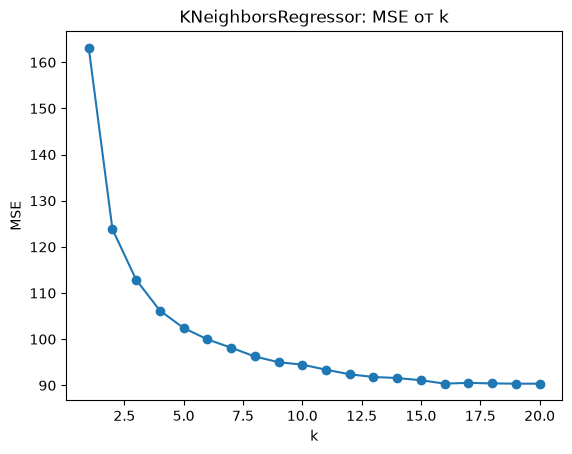

In [116]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

#  total_day_charge = total_day_minutes × rate — прямая производная.
# Если оставить total_day_minutes в признаках, KNN «предсказывает» charge идеально
# (это таргет-утечка). Поэтому берём только НЕзависимые признаки.
features = [
    'total_day_calls',
    'total_eve_minutes', 'total_eve_calls',
    'total_night_minutes', 'total_night_calls',
    'total_intl_minutes', 'total_intl_calls',
]
Xr = df_clean[features].values # df_clean создан в начале ноутбука
yr = df_clean['total_day_charge'].values

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.2, random_state=42
)
sc = MinMaxScaler().fit(Xr_train)
Xr_train_s = sc.transform(Xr_train)
Xr_test_s  = sc.transform(Xr_test)

mse_list = []
for k in range(1, 21):
    reg = KNeighborsRegressor(n_neighbors=k).fit(Xr_train_s, yr_train)
    mse_list.append((k, mean_squared_error(yr_test, reg.predict(Xr_test_s))))

best = min(mse_list, key=lambda t: t[1])
print(f'best k={best[0]}, MSE={best[1]:.3f}')

plt.plot([x[0] for x in mse_list], [x[1] for x in mse_list], marker='o')
plt.xlabel('k'); plt.ylabel('MSE')
plt.title('KNeighborsRegressor: MSE от k')
plt.show()

 total_day_minutes убран иначе MSE получается нереально низким (~6.8 при масштабе charge ≈ 0–60, т.е. почти идеальное предсказание). Это классическая target leakage.

### Упражнение 12: Пайплайны машинного обучения с `Pipeline` и `GridSearchCV`
Постройте полный пайплайн в Scikit-learn, включающий: (1) `MinMaxScaler`, (2) опционально селектор признаков (`SelectKBest`) и (3) `KNeighborsClassifier`. Используйте `GridSearchCV` для одновременного поиска оптимальных гиперпараметров: количества соседей K in {3, 5, 7, 9, 11}, типа весов (`uniform`, `distance`) и метрики расстояния (p=1 или p=2). Выведите лучший набор гиперпараметров и оценку на тестовой выборке.

In [117]:
import pandas as pd
from sklearn.preprocessing import LabelBinarizer, MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv('data/Orange_Telecom_Churn_Data.csv')
df = df.drop(['state', 'area_code', 'phone_number'], axis=1)

lb = LabelBinarizer()
for c in ['intl_plan', 'voice_mail_plan', 'churned']:
    df[c] = lb.fit_transform(df[c])

X = df.drop(columns=['churned'])
y = df['churned']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pipe = Pipeline([
    ('scaler', MinMaxScaler()),
    ('select', SelectKBest(score_func=f_classif)),
    ('knn', KNeighborsClassifier()),
])

n_features = X_train.shape[1]
param_grid = {
    'select__k': [5, 10, n_features],       # варианты k для SelectKBest
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='accuracy')
grid.fit(X_train, y_train)

print('Best params:   ', grid.best_params_)
print('Best CV score: ', round(grid.best_score_, 4))
print('Test score:    ', round(grid.score(X_test, y_test), 4))

Best params:    {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform', 'select__k': 10}
Best CV score:  0.9195
Test score:     0.913
